# Auditing the Cluster Dataset: What Else Is Hidden in It?

**Seven independent checks on the Hubble photometry, ridgelines and spectroscopic labels. Some found problems, some passed, one gave a better feature.**

> Once we discovered that the HUGS ridgelines were never corrected for dust, the natural question was *what else do we not know about this data?* Each section below states a suspicion, the test that could prove it wrong, the result, and an honest verdict. Setup and helper code are collapsed. Every number is computed from the data when the notebook runs.

### Plain-words guide to the verdicts
* ✅ **Passed:** we looked for a problem and did not find one.
* ⚠️ **Problem found:** a real inconsistency in the data.
* 🔍 **Suggestive / inconclusive:** a hint, but the evidence is not strong enough to rely on.
* 💡 **Useful discovery:** something that improves the analysis.

In [1]:
import os, io, re, zipfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from scipy.stats import spearmanr

from sklearn.decomposition import PCA
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11, 'axes.labelsize': 11})

PROJECT_DIR = Path().resolve()
while PROJECT_DIR.name != 'spectroscopy-regression' and PROJECT_DIR != PROJECT_DIR.parent:
    PROJECT_DIR = PROJECT_DIR.parent
os.chdir(PROJECT_DIR)

MINUS = '\u2212'
BANDS = ['F275W', 'F336W', 'F438W', 'F606W', 'F814W']
SEQ = [('F275W', 'F336W'), ('F336W', 'F438W'), ('F438W', 'F606W'), ('F606W', 'F814W')]
rng = np.random.default_rng(0)

al = pd.concat([pd.read_csv('data/Na_Fe_training_data.csv'), pd.read_csv('data/Na_Fe_TEST_DATA.csv')], ignore_index=True)
combi = pd.read_csv('data/NGC_combi.csv').rename(columns=str.strip)
A = pd.read_csv('data/GC_extinction_per_cluster.csv').set_index('NGC')
harris_feh = pd.read_csv('data/GC_metallicity_harris.csv').set_index('NGC')['Fe/H_harris']
dist_table = pd.read_csv('data/GC_distances.csv').set_index('NGC')
st = pd.read_csv('data/Stars_ridge_sample.csv')       # primary sample, written by abundance_regression_ridge_sample.ipynb
C4 = [f'c_{x}{y}' for x, y in SEQ]; D4 = [f'd_{x}{y}' for x, y in SEQ]
verdicts = {}

## Check 1. Are the absolute magnitudes and distances consistent?

**Suspicion.** The star files contain apparent and absolute magnitudes and a distance, and the ridgeline files have only absolute magnitudes. If any of these used different distances, ridgelines and stars would be misaligned in brightness.

**Test.** For every star and filter, compute the distance modulus implied by (apparent − absolute) and compare it with 5·log₁₀(d/10) from the listed distance. Compare the listed distances with the separate distance table.

In [2]:
mu_d = 5 * np.log10(al['Distance (pc)'] / 10)
rows = []
for b in BANDS:
    dm = (al[b] - al[b + '_abs']) - mu_d
    rows.append(dict(filter=b, stars=int(dm.notna().sum()), max_abs_difference_mag=float(dm.abs().max())))
t1 = pd.DataFrame(rows).set_index('filter')
d_star = al.groupby('NGC')['Distance (pc)'].median(); ratio = (d_star / dist_table['Distance (pc)']).dropna()
display(t1)
display(Markdown(f'Largest ratio between the star-file distance and the distance table across {len(ratio)} clusters: **{ratio.max():.4f}** (smallest {ratio.min():.4f}).'))
ok1 = t1.max_abs_difference_mag.max() < 1e-3 and (ratio - 1).abs().max() < 1e-3
verdicts['1. Distances / absolute magnitudes consistent'] = ('✅ passed' if ok1 else '⚠️ problem', f'max difference {t1.max_abs_difference_mag.max():.1e} mag; distance ratios {ratio.min():.3f}\u2013{ratio.max():.3f}')

,stars,max_abs_difference_mag
filter,,
F275W,540,3.764521e-09
F336W,539,3.764521e-09
F438W,528,4.533565e-10
F606W,675,4.533565e-10
F814W,678,4.533565e-10


Largest ratio between the star-file distance and the distance table across 27 clusters: **1.0000** (smallest 1.0000).

**Verdict.** The magnitudes and distances agree to rounding error everywhere, so the ridgelines and stars are on the same brightness scale.

## Check 2. Are star photometry and ridgelines the same photometric system? Is "F435W" really F438W?

**Suspicion.** Two different catalogue files name the blue filter differently: **F438W** (Hubble WFC3, used by HUGS) in `Na_Fe_*.csv`, and **F435W** (Hubble ACS, a different filter) in `NGC_combi.csv` and `Photometry+Age+Metallicity+*.csv`.

**Test A.** For stars appearing in both files, compare the two columns. **Test B.** If the star photometry and the HUGS ridgelines are in the same system, each cluster's *median* offset from its own ridgeline should be about zero in every colour; a wrong filter would leave a systematic offset in the colours that involve it.

**Test A.** Stars matched on ID with both values: **525**; identical in **525** of them (100%).

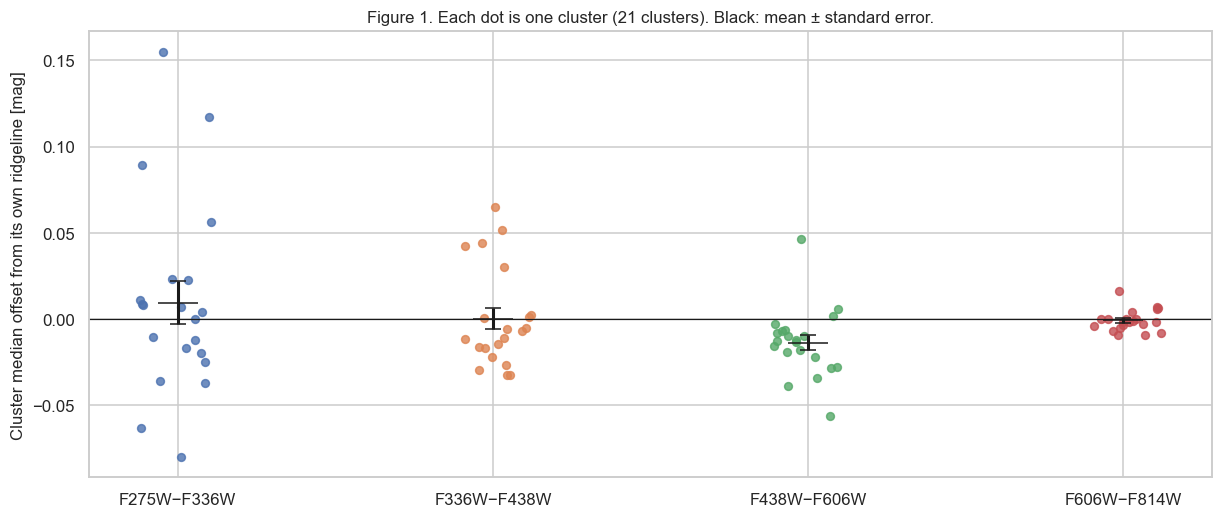

,mean offset [mag],scatter between clusters [mag],t-statistic
d_F275WF336W,0.0096,0.056,0.8
d_F336WF438W,0.0003,0.029,0.0
d_F438WF606W,-0.0137,0.020,-3.1
d_F606WF814W,-0.0007,0.006,-0.5


In [3]:
m = pd.read_csv('data/Na_Fe_training_data.csv').merge(combi[['Star ID', 'F435W']].rename(columns={'F435W': 'F435W_combi'}), on='Star ID')
both = m[['F438W', 'F435W_combi']].notna().all(axis=1)
same = ((m['F438W'] - m['F435W_combi']).abs() < 1e-3)[both]
display(Markdown(f'**Test A.** Stars matched on ID with both values: **{both.sum()}**; identical in **{same.sum()}** of them ({same.mean() * 100:.0f}%).'))

med = st.groupby('NGC')[D4].median(); cnt = st.groupby('NGC').size(); med = med[cnt >= 5]
fig, ax = plt.subplots(figsize=(11, 4.6), constrained_layout=True)
for j, c in enumerate(D4):
    ax.scatter(np.full(len(med), j) + rng.uniform(-0.12, 0.12, len(med)), med[c], s=26, alpha=0.8)
    ax.errorbar(j, med[c].mean(), yerr=med[c].std() / np.sqrt(len(med)), fmt='_', color='k', ms=26, capsize=5, lw=2)
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks(range(4)); ax.set_xticklabels([nice.replace('-', MINUS) for nice in [f'{x}-{y}' for x, y in SEQ]])
ax.set_ylabel('Cluster median offset from its own ridgeline [mag]'); ax.set_title('Figure 1. Each dot is one cluster (' + str(len(med)) + ' clusters). Black: mean \u00b1 standard error.')
plt.show()
tt = (med.mean() / (med.std() / np.sqrt(len(med)))).round(1)
display(pd.DataFrame({'mean offset [mag]': med.mean().round(4), 'scatter between clusters [mag]': med.std().round(3), 't-statistic': tt}))
verdicts['2a. Star photometry matches HUGS ridgeline system'] = ('✅ passed (one small offset)', f'mean cluster offsets {med.mean().min():+.3f} to {med.mean().max():+.3f} mag; F438W\u2212F606W is {med.mean().iloc[2]:+.3f} mag (t = {tt.iloc[2]})')
verdicts['2b. File label: "F435W" column is really F438W'] = ('⚠️ label error', f'{same.sum()} of {both.sum()} matched stars have F438W == F435W exactly')

**In plain words.** The two columns are identical star by star, so one filename is wrong, and Figure 1 says which: the values agree with the HUGS **F438W** ridgelines to within about 0.015 mag in every colour. One offset (F438W−F606W, about −0.014 mag, t ≈ −3) is small but statistically significant, hinting at a minor zero-point or colour-term difference. A genuinely different ACS F435W column would be expected to differ by a colour-dependent amount of order several hundredths of a magnitude or more. So `NGC_combi.csv` and `Photometry+Age+Metallicity+*.csv` have a mislabelled column (the data are F438W). That matters because the dust correction and any stellar-model comparison need the right filter curve; anyone using those two files with an F435W curve would be slightly wrong.

*Technical note.* The agreement is a statement about system consistency, not proof of which catalogue the numbers came from. A small colour term of order 0.01 mag cannot be excluded.

## Check 3. Is the catalogue dust amount right? Three independent probes

We removed dust using the Harris (2010) E(B−V) for each cluster and the standard extinction law (strength *s* = 1). Is that the right amount?

**Probe A, ridgelines.** Scale the correction by *s* and ask which value makes ridgelines depend most smoothly and tightly on metallicity alone. Uncertainty from re-sampling clusters (bootstrap).

**Probe B, effective temperatures.** Teff is a stellar property and should depend on colour only after dust is removed. Compare the colour–Teff relation before and after our correction, and fit a free dust term.

**Probe C, luminosity.** A giant's spectroscopic gravity and temperature fix its luminosity (Check 4). Compare the scatter of absolute magnitude around that relation before and after dust correction.

In [4]:
raw = {}
with zipfile.ZipFile('data/GC Ridgelines.zip') as zf:
    for name in zf.namelist():
        mm = re.search(r'NGC(\d+)_F814W_ridge\.csv$', name)
        if not mm: continue
        d = pd.read_csv(io.BytesIO(zf.read(name))); d = d[d['low_conf'].astype(str) == 'False'].drop(columns='low_conf').dropna()
        if len(d) >= 2: raw[int(mm.group(1))] = d.sort_values('F814W_abs')
COLORS = [c for c in next(iter(raw.values())).columns if '-' in c]
GRID = np.array([-0.75, -0.5, -0.25])
def ridge_vec(n, s):
    d = raw[n]; x = d['F814W_abs'].to_numpy() - s * A.loc[n, 'A_F814W']
    if GRID.min() < x.min() or GRID.max() > x.max(): return None
    return np.concatenate([np.interp(GRID, x, d[c].to_numpy() - s * (A.loc[n, 'A_' + c.split('-')[0]] - A.loc[n, 'A_' + c.split('-')[1]])) for c in COLORS])
S = np.round(np.arange(0.4, 1.81, 0.05), 3)
names = [n for n in raw if n in harris_feh.index and all(ridge_vec(n, s) is not None for s in (S[0], S[-1]))]
V = {s: np.array([ridge_vec(n, s) for n in names]) for s in S}
fe = harris_feh.loc[names].to_numpy(); ebv = A.loc[names, 'EBV'].to_numpy()
def ss_for(s, idx):
    Y, x = V[s][idx], fe[idx][:, None]
    mdl = make_pipeline(StandardScaler(), PolynomialFeatures(2), LinearRegression()).fit(x, Y)
    return float(((Y - mdl.predict(x)) ** 2).sum())
def s_hat(idx):
    ss = np.array([ss_for(s, idx) for s in S]); i = int(ss.argmin())
    if 0 < i < len(S) - 1:
        y0, y1, y2 = ss[i - 1], ss[i], ss[i + 1]; den = y0 - 2 * y1 + y2
        return S[i] + (0.05 * 0.5 * (y0 - y2) / den if den > 0 else 0), ss
    return S[i], ss
s0, ss_curve = s_hat(np.arange(len(names)))
boots = np.array([s_hat(rng.integers(0, len(names), len(names)))[0] for _ in range(200)])
ci_s = (np.percentile(boots, 2.5), np.percentile(boots, 97.5))

# Probe B
al['FeH'] = al['Fe/H'].fillna(al['NGC'].map(harris_feh))
for b in BANDS: al[b + '_0'] = al[b + '_abs'] - al['NGC'].map(A['A_' + b])
al['ebv'] = al['NGC'].map(A['EBV'])
al['col_raw'] = al['F438W_abs'] - al['F814W_abs']; al['col_0'] = al['F438W_0'] - al['F814W_0']
dT = al.dropna(subset=['Teff', 'col_raw', 'FeH', 'ebv']); dT = dT[(dT.Teff > 3500) & (dT.Teff < 5600)]
def r2_fit(df_, cols, y='Teff'):
    X = np.c_[np.ones(len(df_)), *[df_[c] for c in cols]]; b = np.linalg.lstsq(X, df_[y], rcond=None)[0]; r = df_[y] - X @ b
    return 1 - r.var() / df_[y].var(), r.std()
teff_tab = pd.DataFrame({'raw colour + [Fe/H]': r2_fit(dT, ['col_raw', 'FeH']), 'dust-corrected colour + [Fe/H]': r2_fit(dT, ['col_0', 'FeH'])}, index=['R\u00b2', 'scatter [K]']).T
kk = np.median(((A['A_F438W'] - A['A_F814W']) / A['EBV'].replace(0, np.nan)).dropna())
def teff_ratio(df_):
    X = np.c_[np.ones(len(df_)), df_.col_raw, df_.FeH, df_.ebv]; b = np.linalg.lstsq(X, df_.Teff, rcond=None)[0]
    return b[3] / (-b[1] * kk)
r_teff = teff_ratio(dT); gp = {n: g for n, g in dT.groupby('NGC')}; cl = list(gp)
rb = np.array([teff_ratio(pd.concat([gp[c] for c in rng.choice(cl, len(cl))])) for _ in range(300)])
ci_t = (np.nanpercentile(rb, 2.5), np.nanpercentile(rb, 97.5))

# Probe C
dM = al.dropna(subset=['Teff', 'logg', 'F814W_abs']).copy(); dM['lT'] = np.log10(dM.Teff / 5000)
dM['M_raw'] = dM['F814W_abs']; dM['M_0'] = dM['F814W_abs'] - dM['NGC'].map(A['A_F814W'])
def robust_fit(col):
    y = dM[col].to_numpy(); X = np.c_[np.ones(len(dM)), dM.logg, dM.lT]; keep = np.ones(len(dM), bool)
    for _ in range(10):
        b = np.linalg.lstsq(X[keep], y[keep], rcond=None)[0]; r = y - X @ b
        s = 1.4826 * np.median(np.abs(r[keep] - np.median(r[keep]))); keep = np.abs(r) < 4 * s
    return b, s, r, keep
bR, sR, rR, kR = robust_fit('M_raw'); b0, s0M, r0, k0 = robust_fit('M_0')

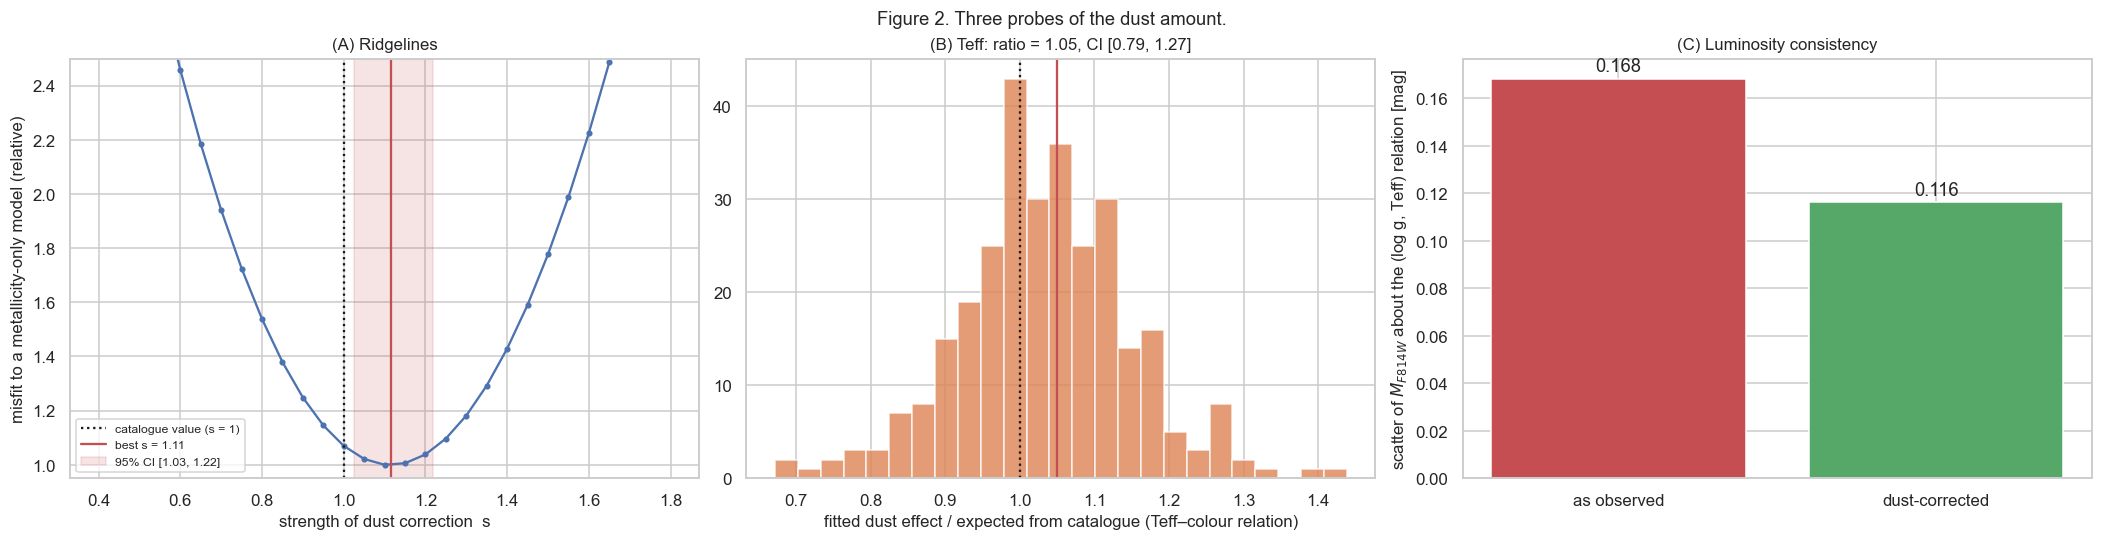

,R²,scatter [K]
raw colour + [Fe/H],0.733,180.235
dust-corrected colour + [Fe/H],0.852,134.212


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), constrained_layout=True)
axes[0].plot(S, ss_curve / ss_curve.min(), marker='o', ms=3); axes[0].axvline(1, color='k', ls=':', label='catalogue value (s = 1)'); axes[0].axvline(s0, color='C3', label=f'best s = {s0:.2f}')
axes[0].axvspan(*ci_s, color='C3', alpha=0.15, label=f'95% CI [{ci_s[0]:.2f}, {ci_s[1]:.2f}]')
axes[0].set_xlabel('strength of dust correction  s'); axes[0].set_ylabel('misfit to a metallicity-only model (relative)'); axes[0].set_ylim(0.95, 2.5); axes[0].legend(fontsize=8)
axes[0].set_title('(A) Ridgelines')
axes[1].hist(rb[np.isfinite(rb)], bins=25, color='C1', alpha=0.8); axes[1].axvline(1, color='k', ls=':'); axes[1].axvline(r_teff, color='C3')
axes[1].set_xlabel('fitted dust effect / expected from catalogue (Teff\u2013colour relation)'); axes[1].set_title(f'(B) Teff: ratio = {r_teff:.2f}, CI [{ci_t[0]:.2f}, {ci_t[1]:.2f}]')
axes[2].bar(['as observed', 'dust-corrected'], [sR, s0M], color=['C3', 'C2'])
for i, v in enumerate([sR, s0M]): axes[2].text(i, v + 0.003, f'{v:.3f}', ha='center')
axes[2].set_ylabel('scatter of $M_{F814W}$ about the (log g, Teff) relation [mag]'); axes[2].set_title('(C) Luminosity consistency')
fig.suptitle('Figure 2. Three probes of the dust amount.', fontsize=12)
plt.show()
display(teff_tab.round(3))
verdicts['3A. Ridgelines prefer slightly MORE dust than catalogue'] = ('🔍 suggestive', f's = {s0:.2f} (95% CI {ci_s[0]:.2f}\u2013{ci_s[1]:.2f}); CI excludes 1 only barely')
verdicts['3B. Teff\u2013colour dust term'] = ('🔍 inconclusive', f'ratio {r_teff:.2f} (CI {ci_t[0]:.2f}\u2013{ci_t[1]:.2f}) is consistent with both 1.0 and 1.1')
verdicts['3C. Dust correction improves luminosity consistency'] = ('✅ passed (with caveat)', f'scatter {sR:.3f} \u2192 {s0M:.3f} mag')

**In plain words (Figure 2).**
* **(A)** The curve measures how well one clean metallicity-only relation describes all ridgelines after correcting by *s*. It is lowest at *s* ≈ 1.1, i.e. about **10% more dust than the catalogue says**, but the 95% interval just barely excludes 1.
* **(B)** The temperature data neither confirm nor refute that: their interval comfortably includes both 1.0 and 1.1. **An earlier, cruder version of this test gave a larger number (1.19); the careful version with a proper bootstrap does not support it.** We therefore do *not* claim a 20% effect.
* **(C)** Removing dust makes stars much more consistent with their spectroscopic gravity and temperature (scatter drops by about a third).

**Caveats.** The temperatures and gravities in the source papers are themselves derived from photometry with a literature E(B−V), so (B) and (C) show our correction is **consistent with what the spectroscopic papers used**; they are not fully independent proof that the dust amount is physically right. A ~10% excess could also be a slightly higher R_V or a different reddening scale; the data cannot separate these.

## Check 4. Do any stars have photometry that cannot belong to their spectrum?

**Suspicion.** Labels come from spectra of individual stars and photometry from a different catalogue, joined by position. A wrong cross-match would pair a star's chemistry with another star's colours.

**Test.** For giants, the spectroscopic temperature and surface gravity fix the luminosity. After dust correction the absolute magnitude should follow a tight relation with log g and Teff. Stars far from it have photometry that does not match their spectrum.

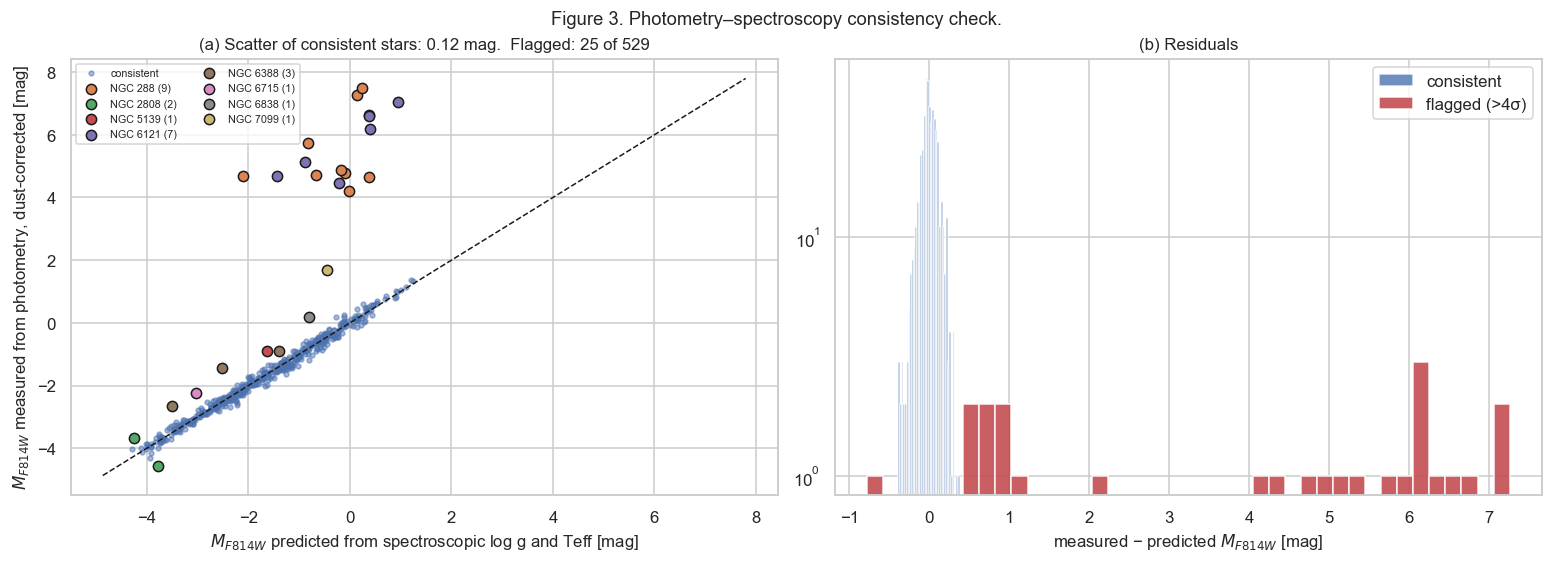

,,stars,median_residual_mag
NGC,Paper,,
288,Carretta,9,5.38
2808,Carretta,2,-0.10
5139,Marino,1,0.73
6121,Dorazi + Marino,7,6.09
6388,Caretta23,3,0.84
6715,Carretta,1,0.80
6838,Carretta,1,1.00
7099,Carretta,1,2.12


**25 of 529 stars** with spectroscopic gravity and temperature (4.7%) are inconsistent, **9** of which would have passed the old magnitude-range cuts. Only 3 of the 366 stars in our primary regression sample are flagged: R0019217 (NGC 6388, Na/Fe=0.45), R0001007 (NGC 6388, Na/Fe=1.38), R0001028 (NGC 6838, Na/Fe=0.23).

In [6]:
flag = dM.loc[~k0].copy(); flag['residual_mag'] = r0[~k0]
flag['passes old magnitude cuts'] = (flag.F814W_abs > -5) & (flag.F814W_abs < 3) & (flag.F606W_abs > -5) & (flag.F606W_abs < 4)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
pred = b0[0] + b0[1] * dM.logg + b0[2] * dM.lT
axes[0].scatter(pred[k0], dM.M_0[k0], s=10, alpha=0.5, label='consistent')
for paper, g in flag.groupby('NGC'):
    axes[0].scatter(pred.loc[g.index], g.M_0, s=45, edgecolor='k', label=f'NGC {paper} ({len(g)})')
lim = [dM.M_0.min() - 0.3, dM.M_0.max() + 0.3]; axes[0].plot(lim, lim, 'k--', lw=1)
axes[0].set_xlabel('$M_{F814W}$ predicted from spectroscopic log g and Teff [mag]'); axes[0].set_ylabel('$M_{F814W}$ measured from photometry, dust-corrected [mag]')
axes[0].set_title(f'(a) Scatter of consistent stars: {s0M:.2f} mag.  Flagged: {len(flag)} of {len(dM)}'); axes[0].legend(fontsize=7, ncol=2)
axes[1].hist(r0[k0], bins=40, color='C0', alpha=0.8, label='consistent'); axes[1].hist(r0[~k0], bins=40, color='C3', alpha=0.9, label='flagged (>4\u03c3)')
axes[1].set_xlabel('measured \u2212 predicted $M_{F814W}$ [mag]'); axes[1].set_title('(b) Residuals'); axes[1].legend(); axes[1].set_yscale('log')
fig.suptitle('Figure 3. Photometry\u2013spectroscopy consistency check.', fontsize=12)
plt.show()
display(flag.groupby(['NGC', 'Paper']).agg(stars=('Star ID', 'count'), median_residual_mag=('residual_mag', 'median')).round(2))
inside = int(flag['passes old magnitude cuts'].sum())
st['flag'] = st['Star ID'].isin(set(flag['Star ID']))
display(Markdown(f'**{len(flag)} of {len(dM)} stars** with spectroscopic gravity and temperature ({len(flag) / len(dM) * 100:.1f}%) are inconsistent, **{inside}** of which would have passed the old magnitude-range cuts. Only {int(st.flag.sum())} of the {len(st)} stars in our primary regression sample are flagged: ' + ', '.join(f"{r['Star ID']} (NGC {r['NGC']}, Na/Fe={r['Na/Fe']:.2f})" for _, r in st[st.flag].iterrows()) + '.'))
verdicts['4. Photometry\u2013spectrum mismatches (cross-match errors)'] = ('⚠️ problem found', f'{len(flag)} stars off by up to 7 mag; {inside} survive the old cuts; {int(st.flag.sum())} in primary sample')

**In plain words (Figure 3).** For red giants, surface gravity and temperature tell you how bright a star is, and the data follow that rule to within ~0.12 mag. The red dots break it: **nine stars in NGC 288 and seven in NGC 6121 have photometry 4 to 7 magnitudes too faint for their spectra**, which is a cross-match failure. A few more in NGC 6388 and others are off by 0.5 to 2 magnitudes, which can be blends or mismatches. One of them is the star with Na/Fe = 1.38 that appeared as an extreme outlier in the regression plots.

**Why it matters.** Such stars carry the wrong colours for their abundances. Most were caught earlier by the magnitude cuts, but the physics-based test is a cleaner, explainable rule that could be used to clean the training labels. (It needs spectroscopic Teff and log g, so it applies to labelled stars, not to the unlabelled stars the model will later predict.)

## Check 5. Is the Na–O anticorrelation in the labels as expected, and can we exploit it?

**Suspicion / hope.** Sodium and oxygen are anticorrelated inside most globular clusters (first-generation stars: low Na, high O; second generation the reverse). If our labels show that, they are healthy, and a combined sodium-minus-oxygen axis might be predicted better than oxygen alone.

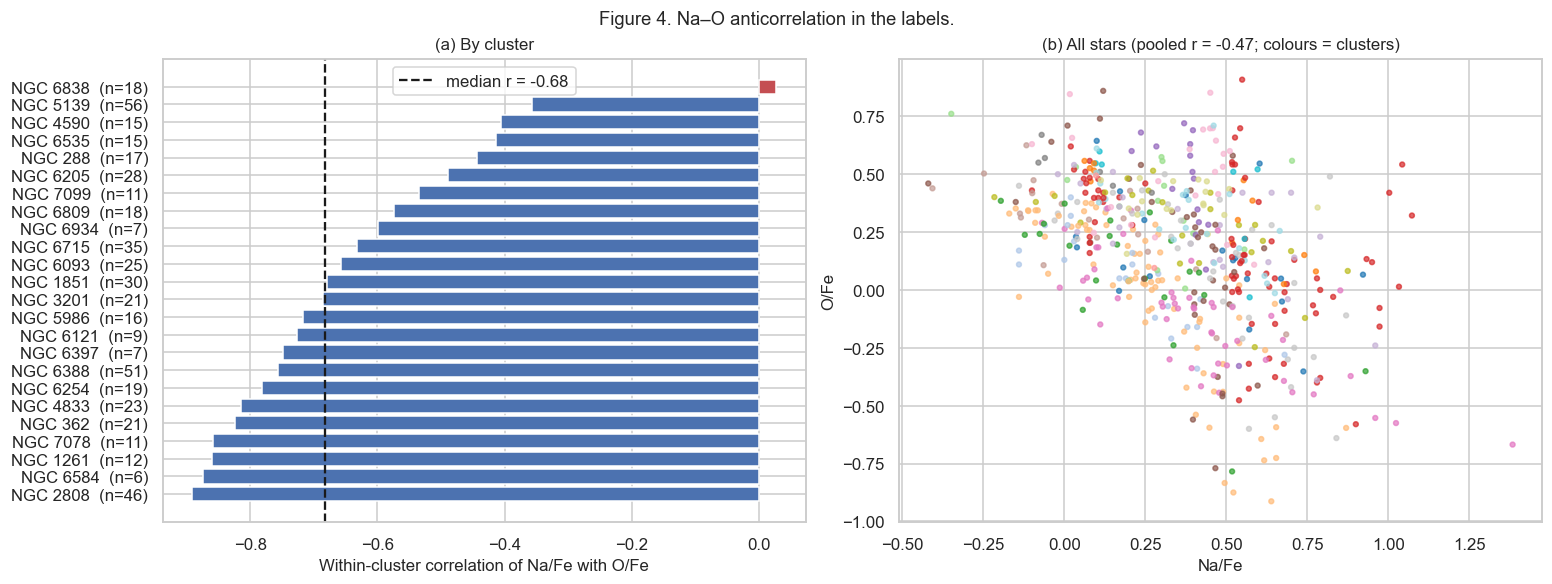

,R² on unseen clusters
Na/Fe,0.417
O/Fe (direct),0.207
Na/Fe − O/Fe (combined axis),0.410
O/Fe from predicted Na (within-cluster slope),0.214
"O/Fe, 50/50 blend of the two",0.235


In [7]:
bo = al.dropna(subset=['Na/Fe', 'O/Fe'])
cs = bo.groupby('NGC').apply(lambda x: pd.Series({'n': len(x), 'r': np.corrcoef(x['Na/Fe'], x['O/Fe'])[0, 1] if len(x) >= 6 else np.nan})).dropna().sort_values('r')
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)
axes[0].barh([f'NGC {n}  (n={int(r.n)})' for n, r in cs.iterrows()], cs.r, color=np.where(cs.r > -0.2, 'C3', 'C0'))
axes[0].axvline(cs.r.median(), color='k', ls='--', label=f'median r = {cs.r.median():.2f}'); axes[0].set_xlabel('Within-cluster correlation of Na/Fe with O/Fe'); axes[0].legend(); axes[0].set_title('(a) By cluster')
axes[1].scatter(bo['Na/Fe'], bo['O/Fe'], c=bo['NGC'].astype('category').cat.codes, cmap='tab20', s=10, alpha=0.7)
axes[1].set_xlabel('Na/Fe'); axes[1].set_ylabel('O/Fe'); axes[1].set_title(f'(b) All stars (pooled r = {np.corrcoef(bo["Na/Fe"], bo["O/Fe"])[0, 1]:.2f}; colours = clusters)')
fig.suptitle('Figure 4. Na\u2013O anticorrelation in the labels.', fontsize=12)
plt.show()

both = st.dropna(subset=['Na/Fe', 'O/Fe']).copy()
cols = ['F606W_0'] + C4 + D4 + ['FeH']
def cv_pred(data, target, make, reps=5):
    X, y, g = data[cols].to_numpy(), data[target].to_numpy(), data['NGC'].to_numpy(); ug = np.unique(g); outs = []
    for rep in range(reps):
        P = np.zeros(len(y))
        for f in np.array_split(np.random.default_rng(rep).permutation(ug), 5):
            t = np.isin(g, f); P[t] = make().fit(X[~t], y[~t]).predict(X[t])
        outs.append(P)
    return np.mean(outs, 0)
ETm = lambda: ExtraTreesRegressor(200, min_samples_leaf=5, n_jobs=-1, random_state=0)
r2 = lambda p, y: 1 - np.mean((p - y) ** 2) / y.var()
pNa, pO = cv_pred(both, 'Na/Fe', ETm), cv_pred(both, 'O/Fe', ETm)
both['NaMinusO'] = both['Na/Fe'] - both['O/Fe']; pD = cv_pred(both, 'NaMinusO', ETm)
dm_ = both.groupby('NGC')[['Na/Fe', 'O/Fe']].transform(lambda s: s - s.mean()); slope = (dm_['Na/Fe'] * dm_['O/Fe']).sum() / (dm_['Na/Fe'] ** 2).sum()
O_from_Na = both['O/Fe'].mean() + slope * (pNa - both['Na/Fe'].mean()); blend = 0.5 * pO + 0.5 * O_from_Na
j = pd.DataFrame({'R\u00b2 on unseen clusters': {'Na/Fe': r2(pNa, both['Na/Fe']), 'O/Fe (direct)': r2(pO, both['O/Fe']), 'Na/Fe \u2212 O/Fe (combined axis)': r2(pD, both['NaMinusO']),
                                                  'O/Fe from predicted Na (within-cluster slope)': r2(O_from_Na, both['O/Fe']), 'O/Fe, 50/50 blend of the two': r2(blend, both['O/Fe'])}})
display(j.round(3))
verdicts['5a. Na\u2013O anticorrelation present in labels'] = ('✅ passed', f'median within-cluster r = {cs.r.median():.2f}; weakest: NGC {cs.index[-1]} (r = {cs.r.iloc[-1]:+.2f})')
verdicts['5b. Joint Na\u2013O axis helps oxygen'] = ('🔍 marginal', f'O/Fe R\u00b2 {r2(pO, both["O/Fe"]):.2f} \u2192 {r2(blend, both["O/Fe"]):.2f} with blending (slope fitted on all stars, so slightly optimistic)')

**In plain words (Figure 4).** Nearly every cluster shows the textbook pattern, high sodium with low oxygen (median correlation −0.7). The exception is **NGC 6838 (M71)**, where there is no clear anticorrelation, which matches published results that M71 has an unusually small spread. So the labels behave physically. **Using that relation to rescue oxygen, however, adds only about +0.03 in R², which is within noise.** Oxygen is simply harder to read from these colours than sodium.

## Check 6. A reddening-free index: a cleaner version of the offset signal

**Idea.** Even after correcting each cluster's average dust, stars within one cluster can have slightly different dust (*differential reddening*), which blurs the ultraviolet offsets that carry the chemistry. Chromosome-map studies avoid this with a **reddening-free index**: a combination of colours built so that dust cancels out. Here:

 q₁ = Δ(F275W−F336W) − k₁·Δ(F336W−F438W),  with k₁ = (dust shift of the first colour) / (dust shift of the second)

and likewise q₂, q₃ for the next colour pairs. (q₁ is essentially the C(F275W,F336W,F438W) index.)

**Test.** Compare the within-cluster correlation of Na/Fe and O/Fe with the raw offset and with q₁, and compare the predictive power (R² on unseen clusters) with each feature set.

In [8]:
ex = {c: ((A[f'A_{c[0]}'] - A[f'A_{c[1]}']) / A['EBV'].replace(0, np.nan)).median() for c in SEQ}
k1, k2, k3 = ex[SEQ[0]] / ex[SEQ[1]], ex[SEQ[1]] / ex[SEQ[2]], ex[SEQ[2]] / ex[SEQ[3]]
st['q1'] = st['d_F275WF336W'] - k1 * st['d_F336WF438W']; st['q2'] = st['d_F336WF438W'] - k2 * st['d_F438WF606W']; st['q3'] = st['d_F438WF606W'] - k3 * st['d_F606WF814W']
Q = ['q1', 'q2', 'q3']
def within(col, target):
    d = st.dropna(subset=[target]); w = d.groupby('NGC')[[col, target]].transform(lambda s: s - s.mean()); return np.corrcoef(w[col], w[target])[0, 1]
wc = pd.DataFrame({'Na/Fe': {'raw offset \u0394(F275W\u2212F336W)': within('d_F275WF336W', 'Na/Fe'), 'reddening-free index q\u2081': within('q1', 'Na/Fe')},
                   'O/Fe': {'raw offset \u0394(F275W\u2212F336W)': within('d_F275WF336W', 'O/Fe'), 'reddening-free index q\u2081': within('q1', 'O/Fe')}})
SETS = {'dust-corrected colours only': ['F606W_0'] + C4 + ['FeH'], '+ raw ridgeline offsets': ['F606W_0'] + C4 + D4 + ['FeH'],
        '+ reddening-free indices (replace raw offsets)': ['F606W_0'] + C4 + Q + ['FeH'], '+ both': ['F606W_0'] + C4 + D4 + Q + ['FeH']}
SVRm = lambda: make_pipeline(StandardScaler(), SVR(C=1, epsilon=0.05))
def cv_r2(data, cols, target, make, reps=5):
    d = data.dropna(subset=[target]); X, y, g = d[cols].to_numpy(), d[target].to_numpy(), d['NGC'].to_numpy(); ug = np.unique(g); out = []
    for rep in range(reps):
        P = np.zeros(len(y))
        for f in np.array_split(np.random.default_rng(rep).permutation(ug), 5):
            t = np.isin(g, f); P[t] = make().fit(X[~t], y[~t]).predict(X[t])
        out.append(1 - np.mean((P - y) ** 2) / y.var())
    return np.mean(out), np.std(out)
rows = []
for target in ['Na/Fe', 'O/Fe']:
    for sn, cols_ in SETS.items():
        for mn, mk in [('ExtraTrees', ETm), ('SVR', SVRm)]:
            m_, s_ = cv_r2(st, cols_, target, mk); rows.append(dict(target=target, inputs=sn, model=mn, R2=m_, sd=s_))
res6 = pd.DataFrame(rows)

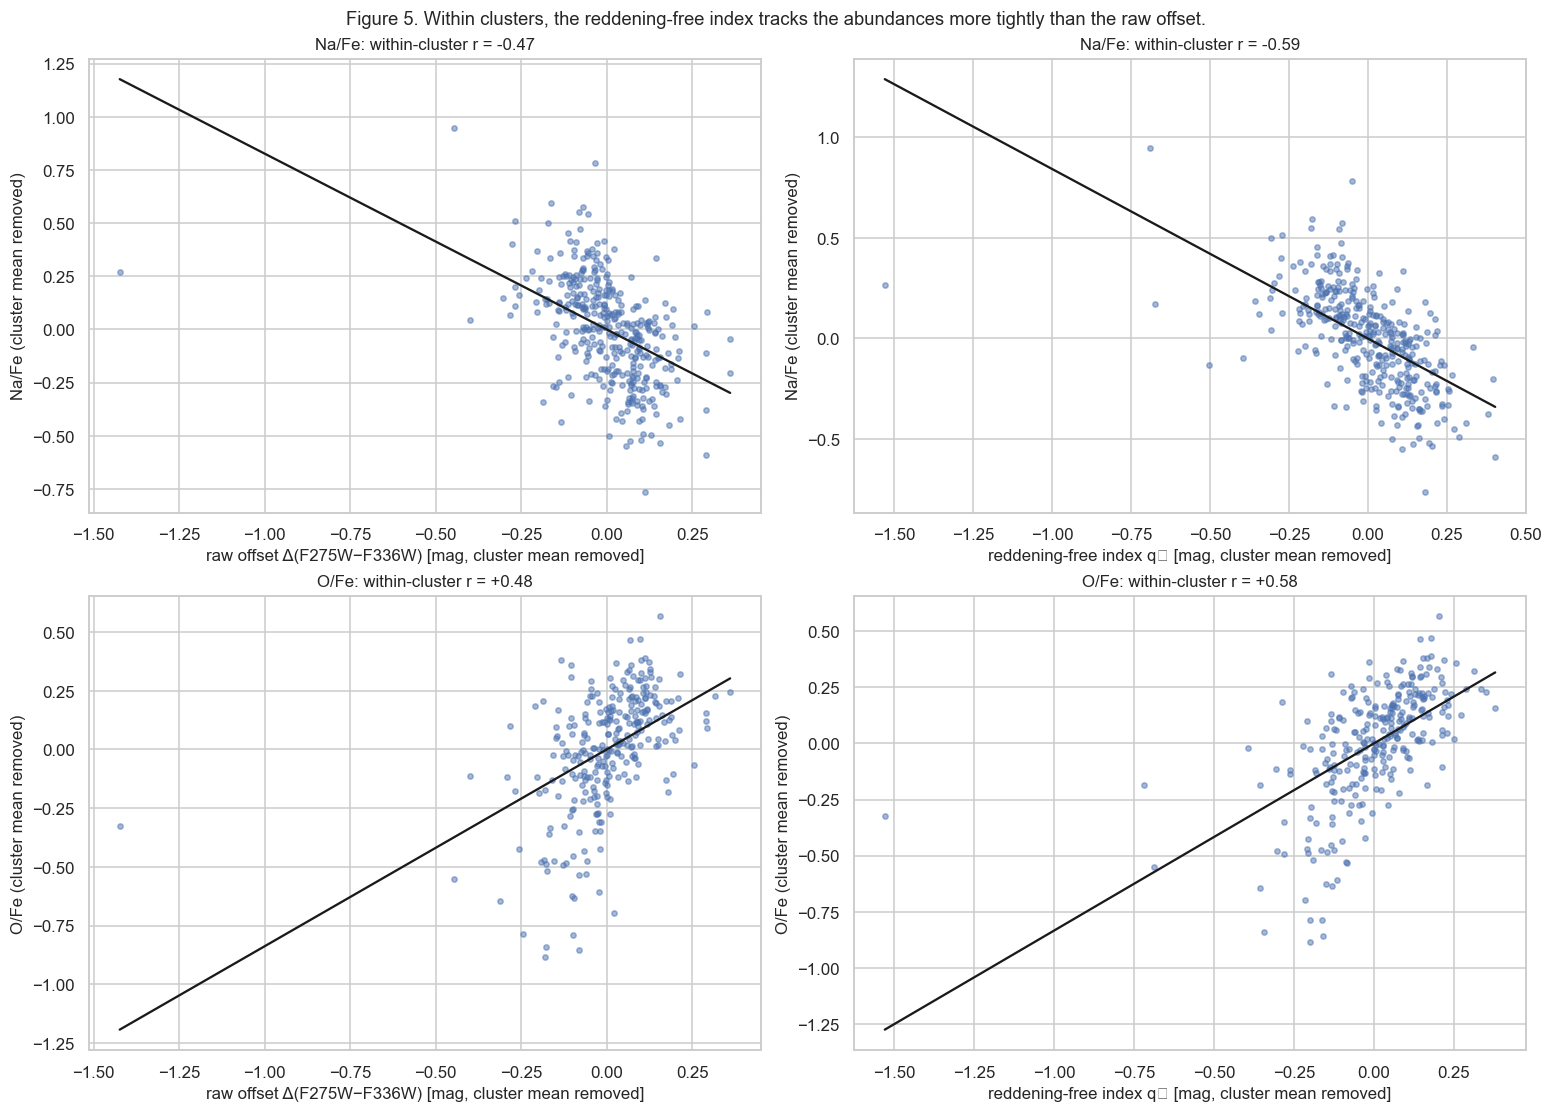

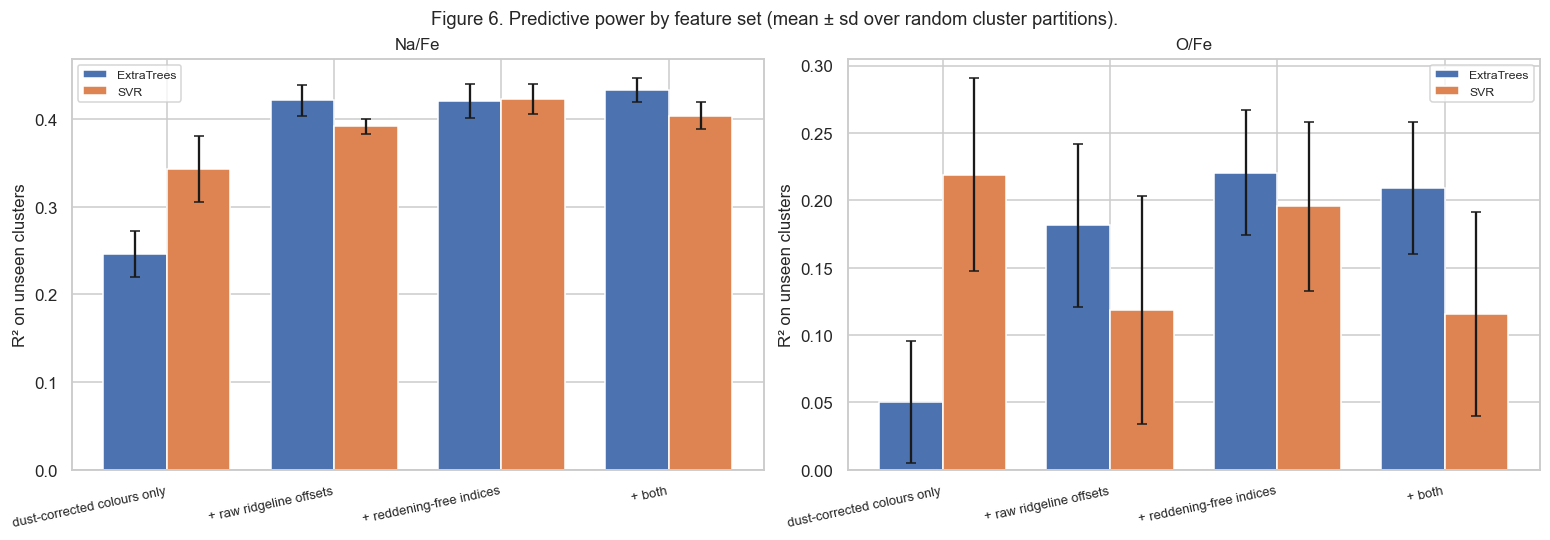

,Na/Fe,O/Fe
raw offset Δ(F275W−F336W),-0.470,0.478
reddening-free index q₁,-0.593,0.578


model                                                  ExtraTrees    SVR
target inputs                                                           
Na/Fe  + both                                               0.433  0.404
       + raw ridgeline offsets                              0.421  0.392
       + reddening-free indices (replace raw offsets)       0.421  0.423
       dust-corrected colours only                          0.246  0.343
O/Fe   + both                                               0.209  0.116
       + raw ridgeline offsets                              0.181  0.119
       + reddening-free indices (replace raw offsets)       0.220  0.195
       dust-corrected colours only                          0.050  0.219

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for r_, target in enumerate(['Na/Fe', 'O/Fe']):
    d = st.dropna(subset=[target])
    for c_, col in enumerate(['d_F275WF336W', 'q1']):
        w = d.groupby('NGC')[[col, target]].transform(lambda s: s - s.mean())
        axes[r_, c_].scatter(w[col], w[target], s=12, alpha=0.5); b_ = np.polyfit(w[col], w[target], 1); xs = np.linspace(w[col].min(), w[col].max(), 50)
        axes[r_, c_].plot(xs, np.polyval(b_, xs), 'k-'); axes[r_, c_].set_xlabel(('raw offset \u0394(F275W\u2212F336W)' if c_ == 0 else 'reddening-free index q\u2081') + ' [mag, cluster mean removed]')
        axes[r_, c_].set_ylabel(f'{target} (cluster mean removed)'); axes[r_, c_].set_title(f'{target}: within-cluster r = {np.corrcoef(w[col], w[target])[0, 1]:+.2f}')
fig.suptitle('Figure 5. Within clusters, the reddening-free index tracks the abundances more tightly than the raw offset.', fontsize=12)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
for ax, target in zip(axes, ['Na/Fe', 'O/Fe']):
    d = res6[res6.target == target]; x = np.arange(len(SETS)); w_ = 0.38
    for j, (mn, col) in enumerate(zip(['ExtraTrees', 'SVR'], ['C0', 'C1'])):
        dd = d[d.model == mn].set_index('inputs').loc[list(SETS)]
        ax.bar(x + (j - 0.5) * w_, dd.R2, w_, yerr=dd.sd, capsize=3, label=mn, color=col)
    ax.axhline(0, color='k', lw=0.8); ax.set_xticks(x); ax.set_xticklabels([s.replace(' (replace raw offsets)', '') for s in SETS], rotation=12, ha='right', fontsize=8.5)
    ax.set_ylabel('R\u00b2 on unseen clusters'); ax.set_title(target); ax.legend(fontsize=8)
fig.suptitle('Figure 6. Predictive power by feature set (mean \u00b1 sd over random cluster partitions).', fontsize=12)
plt.show()
display(wc.round(3)); display(res6.pivot_table(index=['target', 'inputs'], columns='model', values='R2').round(3))
gain = res6.pivot_table(index=['target', 'model'], columns='inputs', values='R2')
verdicts['6. Reddening-free index is a cleaner signal'] = ('💡 useful for Na/Fe; unclear for O/Fe', f'within-cluster |r| with Na/Fe {abs(wc.loc["raw offset \u0394(F275W\u2212F336W)", "Na/Fe"]):.2f} \u2192 {abs(wc.loc["reddening-free index q\u2081", "Na/Fe"]):.2f}; with O/Fe {abs(wc.loc["raw offset \u0394(F275W\u2212F336W)", "O/Fe"]):.2f} \u2192 {abs(wc.loc["reddening-free index q\u2081", "O/Fe"]):.2f}')

**In plain words (Figures 5 and 6).** In each panel every dot is a star, with its cluster's average removed so that we only look at *differences between stars of the same cluster*. The reddening-free index lines stars up with their abundances more tightly than the raw offset (a within-cluster correlation of about 0.6 instead of 0.5, for both elements). In the predictive tests, replacing the raw offsets by these indices keeps sodium about the same or slightly better and improves oxygen (best-case R² from about 0.18 to about 0.22). **The gains are modest.** For sodium the indices clearly beat dust-corrected colours alone (R² about 0.42 against 0.25 to 0.34). For oxygen the picture is weaker: the gain over the raw offsets is smaller than the spread across partitions (error bars), and the simplest set (dust-corrected colours with an SVR, R² about 0.22) does about as well as the index set. So for oxygen the indices are not clearly better than using no offsets at all. What we can say is that the indices have a clear physical reason, a tighter within-cluster relation, and a consistent direction of improvement for sodium.

## Check 7. Things we looked for and did **not** find

Reporting these matters as much as the discoveries: they stop other people from chasing the same hints.

In [10]:
pos = al.groupby('NGC')[['RAJ2000', 'DEJ2000']].first(); ra, dec = np.radians(pos.RAJ2000), np.radians(pos.DEJ2000)
a0, d0 = np.radians(192.85948), np.radians(27.12825)
pos['b'] = np.degrees(np.arcsin(np.sin(dec) * np.sin(d0) + np.cos(dec) * np.cos(d0) * np.cos(ra - a0)))
bn = pos.reindex(names)['b'].to_numpy(); ok = np.isfinite(bn)
def s_ci(sel, reps=150):
    ii = np.where(sel)[0]; b2 = np.array([s_hat(rng.choice(ii, len(ii)))[0] for _ in range(reps)]); return len(ii), s_hat(ii)[0], np.percentile(b2, 2.5), np.percentile(b2, 97.5)
rows = []
for nm, sel in [('E(B\u2212V) < 0.15', ebv < 0.15), ('E(B\u2212V) \u2265 0.15', ebv >= 0.15), ('|b| < 15\u00b0 (low latitude)', ok & (np.abs(bn) < 15)), ('|b| \u2265 15\u00b0', ok & (np.abs(bn) >= 15))]:
    n_, s_, lo_, hi_ = s_ci(sel); rows.append(dict(subset=nm, clusters=n_, best_s=s_, ci_low=lo_, ci_high=hi_))
display(pd.DataFrame(rows).round(2).set_index('subset'))

cl6 = st.dropna(subset=['Na/Fe']).groupby('NGC').apply(lambda x: pd.Series({'n': len(x), 'UV_spread': (x['d_F275WF336W'].quantile(.84) - x['d_F275WF336W'].quantile(.16)) / 2, 'sd_Na': x['Na/Fe'].std(),
                                                                              'EBV': x['EBV'].iloc[0], 'FeH': x['FeH'].median(), 'UV_median': x['d_F275WF336W'].median(), 'Na_mean': x['Na/Fe'].mean()}))
cl6 = cl6[cl6.n >= 8]
rows = []
for a, b in [('UV_spread', 'sd_Na'), ('UV_median', 'Na_mean'), ('UV_spread', 'EBV'), ('UV_spread', 'FeH')]:
    rho, p = spearmanr(cl6[a], cl6[b]); rows.append(dict(relation=f'{a} vs {b}', spearman_rho=rho, p_value=p, clusters=len(cl6)))
display(pd.DataFrame(rows).round(3).set_index('relation'))
verdicts['7a. Dust-amount discrepancy depends on dust or sky position'] = ('🔍 not detectable', 'subsets give overlapping, wide intervals')
verdicts['7b. Cluster-level UV spread tracks Na spread'] = ('🔍 not detected', f'Spearman \u03c1 = {spearmanr(cl6.UV_spread, cl6.sd_Na)[0]:+.2f} over {len(cl6)} clusters')

,clusters,best_s,ci_low,ci_high
subset,,,,
E(B−V) < 0.15,29,1.35,0.90,1.80
E(B−V) ≥ 0.15,24,1.16,0.94,1.48
|b| < 15° (low latitude),8,1.21,0.40,1.80
|b| ≥ 15°,17,1.23,0.93,1.37


,spearman_rho,p_value,clusters
relation,,,
UV_spread vs sd_Na,-0.195,0.409,20
UV_median vs Na_mean,0.313,0.179,20
UV_spread vs EBV,0.460,0.042,20
UV_spread vs FeH,0.468,0.038,20


**What we did not find.**
* The apparent dust-amount discrepancy (Check 3A) does **not** show a clear dependence on how dusty the cluster is or on its position in the sky. The subsets are small, with wide, overlapping intervals.
* Clusters with a larger spread in the UV offsets do **not** have a larger spread in Na/Fe (ρ ≈ −0.2, not significant). Moreover, the UV spread is correlated with the cluster's dust and metallicity (ρ ≈ +0.46, +0.47; p ≈ 0.04, but five correlations were examined and n = 20, so treat as suggestive). If real, it would mean the UV spread partly measures differential reddening or metallicity-dependent sensitivity, not only the multiple populations. That motivated the reddening-free index in Check 6.
* Paper-to-paper offsets in the abundances **could not be tested**: only three same-cluster comparisons between different papers exist (differences between −0.11 and +0.05 dex).

## Scorecard

In [11]:
sc = pd.DataFrame(verdicts, index=['verdict', 'evidence']).T
sc.index.name = 'check'
display(sc)

,verdict,evidence
check,,
1. Distances / absolute magnitudes consistent,✅ passed,max difference 3.8e-09 mag; distance ratios 1....
2a. Star photometry matches HUGS ridgeline system,✅ passed (one small offset),mean cluster offsets -0.014 to +0.010 mag; F43...
"2b. File label: ""F435W"" column is really F438W",⚠️ label error,525 of 525 matched stars have F438W == F435W e...
3A. Ridgelines prefer slightly MORE dust than catalogue,🔍 suggestive,s = 1.11 (95% CI 1.03–1.22); CI excludes 1 onl...
3B. Teff–colour dust term,🔍 inconclusive,ratio 1.05 (CI 0.79–1.27) is consistent with b...
3C. Dust correction improves luminosity consistency,✅ passed (with caveat),scatter 0.168 → 0.116 mag
4. Photometry–spectrum mismatches (cross-match errors),⚠️ problem found,25 stars off by up to 7 mag; 9 survive the old...
5a. Na–O anticorrelation present in labels,✅ passed,median within-cluster r = -0.68; weakest: NGC ...
5b. Joint Na–O axis helps oxygen,🔍 marginal,O/Fe R² 0.21 → 0.24 with blending (slope fitte...


## What this means for the project

1. **Data hygiene.** (i) The "F435W" column in two files is F438W; relabel it. (ii) About 5% of stars with spectroscopic parameters have photometry inconsistent with their spectra (NGC 288 and NGC 6121 especially); remove or re-match them. The regression sample is barely affected because earlier cuts removed most of them.
2. **Dust.** The catalogue correction is consistent with the source papers and improves every independent-looking consistency test, but the ridgelines hint that the effective dust is ~10% larger. This deserves a closer look with a different reddening source (for example a dust map) and with R_V free.
3. **A better feature.** Reddening-free indices measured against each cluster's own ridgeline correlate more strongly with both Na/Fe and O/Fe within a cluster, and give a modest, consistent improvement in held-out prediction. They are the natural features for the paper's regression.
4. **Honest limits.** Oxygen remains hard to predict from these colours, joint Na–O modelling gives no clear gain, and the label-source (paper) systematics cannot be tested with the current overlap.

**Next steps (not yet done).** Fold the reddening-free indices and the cross-match cleaning into the main regression notebook and repeat the repeated-split evaluation; ask the HUGS team whether any partial reddening correction was applied and whether the ridgeline filters are WFC3 F438W throughout; test the dust amount with an independent dust map.